# Воспроизведение гало-орбит по статье Ричардсона

In [49]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import fsolve

from token import COMMA

## Физические константы

В этом разделе определены физические константы, используемые в расчетах, такие как массы Земли, Луны и Солнца, гравитационная постоянная и расстояния между телами. Также здесь рассчитывается безразмерная величина `Mu` (массовое отношение), которая является ключевым параметром в ограниченной круговой задаче трех тел.

In [50]:
class Const:
    """Defines physical constants for the three-body problem."""
    Mass_Earth = 5.9722e24 #kg
    Mass_Moon = 7.3477e22 #kg
    Mass_Sun = 1.988416e30 #kg
    Grav = 6.67430e-11 #CI units
    Dist_Moon =  384399000 #m
    Dist_Sun = 149598261000 #m
    cos30 =( 3 ** 0.5) / 2 # Cosine of 30 degrees
    cos45 =  1 / (2 ** 0.5) # Cosine of 45 degrees
    # Added constants for the Richardson method
    RICHARDSON_LMBDA_GUESS = 1000 # Initial guess for lambda in Richardson method
    RICHARDSON_N_PHASE_DEFAULT = 1 # Default phase parameter for Richardson method
    RICHARDSON_L1_OFFSET_COEFF = 1 # Coefficient for L1 offset in Richardson method
    RICHARDSON_L2_OFFSET_COEFF = 1 # Coefficient for L2 offset in Richardson method
    # Constants for force calculation
    OMEGA_X = 0.0 # X-component of angular velocity
    OMEGA_Y = 0.0 # Y-component of angular velocity
    OMEGA_Z = 1.0 # Z-component of angular velocity (assuming rotation around Z-axis)
    CORIOLIS_COEFF = 2.0 # Coefficient for Coriolis force term
    CENTRIFUGAL_COEFF = 1.0 # Coefficient for centrifugal force term

    # Constants for SolveDI
    TIME_SPAN_START = 0 # Start time for integration
    DEFAULT_TIME_LIMIT = 4 # Default time limit for integration
    DEFAULT_SAMPLING_FREQUENCY = 100000 # Default number of points for the solution
    DEFAULT_RTOL = 1e-9 # Default relative tolerance for ODE solver
    DEFAULT_ATOL = 1e-9 # Default absolute tolerance for ODE solver
    DEFAULT_SOLVER_METHOD = 'Radau' # Default ODE solver method

    # Constants for plotting
    PRIMARY_BODY_COLOR = "red" # Color for primary bodies in plot
    LAGRANGE_POINT_COLOR = "green" # Color for Lagrange points in plot
    TRAJECTORY_COLOR = "blue" # Color for trajectory in plot
    TRAJECTORY_LABEL = "Траектория (x, y, z)" # Label for trajectory in plot
    PRIMARY_BODY_LABEL = "Точки" # Label for primary bodies in plot
    JACOBI_INTEGRAL_LABEL = "Интеграл Якоби" # Label for Jacobi integral plot
    TRAJECTORY_TITLE = "Ограниченная круговая задача трех тел" # Title for trajectory plot
    JACOBI_INTEGRAL_TITLE = "Интеграл Якоби" # Title for Jacobi integral plot
    LIBRATION_NAMES = ["L1", "L2", "L3", "L4", "L5"] # Names of Lagrange points

    # Constants for Jacobi integral calculation
    JACOBI_POTENTIAL_COEFF = 2.0 # Coefficient for potential terms in Jacobi integral

    # Constants for Richardson method (continued)
    RICHARDSON_N_PHASE_1 = 1 # Phase parameter 1 for Richardson method
    RICHARDSON_N_PHASE_3 = 3 # Phase parameter 3 for Richardson method
    RICHARDSON_THETA_DEFAULT = 0.0 # Default theta for Richardson method
    RICHARDSON_DELTA_N_COEFF = 2.0 # Coefficient for delta_n in Richardson method

    # Constants for matrix DI
    MATRIX_DI_N = 6 # Dimension of the state space for matrix DI
    MATRIX_DI_INITIAL_CONDITION = 1.0 # Initial condition for diagonal elements of the identity matrix

    # Constants for correcting initial conditions
    CORRECTION_THRESHOLD = 1e-5 # Threshold for convergence in correction loop
    MAX_CORRECTION_STEPS = 100 # Maximum number of steps in correction loop
    CORRECTION_ARRAY_COEFF = 0.0 # Coefficient for array elements in correction

## Решение полиномов

Класс `Solver5` предназначен для нахождения корней полиномов пятой степени. Это необходимо для точного определения положений точек Лагранжа L1 и L2, которые вычисляются как корни определенных полиномиальных уравнений в ограниченной круговой задаче трех тел. Класс использует функцию `numpy.roots` для нахождения всех корней (включая комплексные) и имеет метод для извлечения только вещественных корней.

In [51]:
class Solver5:
    '''
    Solver for a 5th-degree polynomial of the form a*x^5 + b*x^4 + c*x^3 + d*x^2 + e*x + f = 0.
    Uses numpy to find roots, including complex ones.
    '''
    def __init__(self, Array):
        '''
        Initializes the solver with the polynomial coefficients.

        Args:
            Array (list or np.array): A list or numpy array of coefficients [a, b, c, d, e, f].
        '''
        self.coefficients = Array
        # Calculate all roots (including complex) using numpy's roots function
        self.roots = np.roots(self.coefficients)

    def Roots(self):
        '''
        Returns all roots of the polynomial.

        Returns:
            np.array: An array of all roots (complex128).
        '''
        return self.roots

    def RealRoots(self):
        '''
        Returns only the real roots of the polynomial.

        Returns:
            list: A list of real roots (float).
        '''
        ans = []
        # Iterate through all roots and check if the imaginary part is zero
        for root in self.roots:
            if (root.imag == 0):
                ans.append(root.real)
        return ans

## Расчет точек Лагранжа

Функция `calculate_lagrange_points` вычисляет координаты пяти точек Лагранжа (L1, L2, L3, L4, L5) для заданной системы двух тел с учетом их массового отношения. Точки L1, L2 и L3 лежат на линии, соединяющей два массивных тела, а L4 и L5 образуют с ними равносторонние треугольники. Эти точки являются точками равновесия в ограниченной круговой задаче трех тел.

**Reasoning**:
Add a docstring to the `countlibra` function explaining its purpose and parameters.



In [52]:
def countlibra(GivenMu):
    '''
    Calculates the positions of the five Lagrange points (L1, L2, L3, L4, L5)
    for a given mass ratio (mu).

    Args:
        GivenMu (float): The mass ratio (mu) of the smaller body to the total mass
                         of the two primary bodies.

    Returns:
        list: A list containing three lists, representing the x, y, and z coordinates
              of the five Lagrange points.
              [[x_L1, x_L2, x_L3, x_L4, x_L5],
               [y_L1, y_L2, y_L3, y_L4, y_L5],
               [z_L1, z_L2, z_L3, z_L4, z_L5]]
    '''
    # Calculate L1 point position by finding the real root of a 5th-degree polynomial
    L1 = np.array([1 - GivenMu - float(Solver5([1, -(3 - GivenMu), (3 - 2 * GivenMu), - GivenMu, + (2 * GivenMu), -GivenMu]).RealRoots()[0]), 0, 0])
    # Calculate L2 point position by finding the real root of a 5th-degree polynomial
    L2 = np.array([1 - GivenMu + float(Solver5([1, (3 - GivenMu), (3 - 2 * GivenMu), - GivenMu, -2 * GivenMu, -GivenMu]).RealRoots()[0]), 0, 0])
    # Calculate L3 point position (approximation for small mu)
    L3 = np.array([-GivenMu - 7/12 * GivenMu, 0, 0])
    # Calculate L4 point position (equilateral triangle with primary bodies)
    L4 = np.array([0.5 - GivenMu, Const.cos30, 0])
    # Calculate L5 point position (equilateral triangle with primary bodies)
    L5 = np.array([0.5 - GivenMu, - Const.cos30, 0])

    # Return the coordinates of the Lagrange points
    return [[L1[0], L2[0], L3[0], L4[0], L5[0]],
                 [L1[1], L2[1], L3[1], L4[1], L5[1]],
                 [L1[2], L2[2], L3[2], L4[2], L5[2]]]

## Визуализация результатов

Класс `Plotter` содержит функционал для построения графиков, иллюстрирующих решение ограниченной круговой задачи трех тел. Он позволяет визуализировать траекторию движения маломассивного тела в трехмерном пространстве и отобразить изменение интеграла Якоби со временем. Отображение точек Лагранжа и первичных тел на графике траектории помогает лучше понять контекст движения.

In [53]:
class Plotter:
    '''
    Handles plotting of the trajectory and Jacobi integral for the three-body problem.
    '''
    def __init__(self, three_body_problem):
        '''
        Initializes the plotter with figure and axes for trajectory and Jacobi integral.

        Args:
            three_body_problem (ThreeBodyProblem): An instance of the ThreeBodyProblem class.
        '''
        # Create a 3D figure for the trajectory
        self.__t_fig = plt.figure("Траектория")
        self.__t_ax = self.__t_fig.add_subplot(111, projection='3d')

        # Set labels for the trajectory plot axes
        self.__t_ax.set_xlabel("x(t)")
        self.__t_ax.set_ylabel("y(t)")
        self.__t_ax.set_zlabel("z(t)")
        # self.__t_ax.legend() # Commented out legend as per original code
        plt.title("Ограниченная круговая задача трех тел")

        # Get the dimensionless coordinates of the primary bodies
        xe = -three_body_problem.mu
        ye = 0
        ze = 0

        xm = 1 - three_body_problem.mu
        ym = 0
        zm = 0

        # Plot the primary bodies as red dots
        self.__t_ax.scatter([xe, xm], [ye, ym], [ze, zm], color="red", label="Точки")

        # Add text labels for the primary bodies
        self.__t_ax.text(xe, ye, ze, three_body_problem.bodies[0], color="red")
        self.__t_ax.text(xm, ym, zm, three_body_problem.bodies[1], color="red")

        # Plot the Lagrange points as green dots
        Libration_Names = ["L1", "L2", "L3", "L4", "L5"]
        self.__t_ax.scatter(three_body_problem.Libration[0], three_body_problem.Libration[1], three_body_problem.Libration[2], three_body_problem.bodies[1],
                            color="green")
        # Add text labels for the Lagrange points
        for xi, yi, zi, label in zip(three_body_problem.Libration[0], three_body_problem.Libration[1], three_body_problem.Libration[2], Libration_Names):
            self.__t_ax.text(xi, yi, zi, label, color="green")

        # Set limits for the trajectory plot axes for better visualization
        self.__t_ax.set_xlim([1 - three_body_problem.mu - 0.01, 1 - three_body_problem.mu + 0.01])
        self.__t_ax.set_ylim([-0.01, 0.01])
        self.__t_ax.set_zlim([-0.01, 0.01])

        # Create a 2D figure for the Jacobi integral
        self.__i_fig = plt.figure("Интеграл Якоби")
        self.__i_ax = self.__i_fig.add_subplot()

    def Plot(self, three_body_problem):
        '''
        Plots the trajectory and the Jacobi integral.

        Args:
            three_body_problem (ThreeBodyProblem): An instance of the ThreeBodyProblem class containing the solution.
        '''
        # Plot the trajectory (x, y, z coordinates over time)
        self.__t_ax.plot(three_body_problem.solution.y[0],
                         three_body_problem.solution.y[1],
                         three_body_problem.solution.y[2],
                         label="Траектория (x, y, z)")

        # Plot the Jacobi integral over time
        self.__i_ax.plot(three_body_problem.solution.t,
                         three_body_problem.jacoby_integral)

        plt.show()

## Уравнения движения

Класс `EquationsOfMotion` содержит методы для расчета производных вектора состояния (положение и скорость) для ограниченной круговой задачи трех тел. Он учитывает гравитационное взаимодействие с двумя массивными телами, а также центробежные и кориолисовы силы в вращающейся системе отсчета.

In [54]:
class EquationsOfMotion:
    """Calculates the derivatives of the state vector for the restricted circular three-body problem."""
    def __init__(self, mu):
        """
        Initializes with the mass ratio.

        Args:
            mu (float): The mass ratio.
        """
        self.mu = mu

    def calculate_force(self, t, variables):
        """
        Calculates the derivatives of the state vector (position and velocity).

        Args:
            t (float): Time (dimensionless).
            variables (list or np.array): The current state vector [x, y, z, vx, vy, vz].

        Returns:
            list: The derivatives of the state vector [vx, vy, vz, ax, ay, az].
        """
        x, y, z, vx, vy, vz = variables

        r1 = np.array([-self.mu, 0, 0])
        r2 = np.array([1 - self.mu, 0, 0])
        w = np.array([Const.OMEGA_X, Const.OMEGA_Y, Const.OMEGA_Z])
        r = np.array([x, y, z])
        dr_dt = np.array([vx, vy, vz])

        dr2_dt = (-(1 - self.mu) * (r - r1) / np.linalg.norm(r - r1) ** 3
                  - self.mu * (r - r2) / np.linalg.norm(r - r2) ** 3
                  - Const.CENTRIFUGAL_COEFF * np.cross(w, np.cross(w, r))
                  - Const.CORIOLIS_COEFF * np.cross(w, dr_dt))

        return [dr_dt[0], dr_dt[1], dr_dt[2], dr2_dt[0], dr2_dt[1], dr2_dt[2]]

## Решатель ОДУ

Класс `ODESolver` использует функцию `scipy.integrate.solve_ivp` для численного решения обыкновенных дифференциальных уравнений движения. Он настраивается с помощью уравнений движения и параметров точности, а затем вычисляет траекторию движения маломассивного тела на заданном временном интервале.

In [55]:
class ODESolver:
    """Solves the ordinary differential equations of motion."""
    def __init__(self, equations_of_motion, rtol=Const.DEFAULT_RTOL, atol=Const.DEFAULT_ATOL, method=Const.DEFAULT_SOLVER_METHOD):
        """
        Initializes with the equations of motion and solver settings.

        Args:
            equations_of_motion (EquationsOfMotion): An instance of the EquationsOfMotion class.
            rtol (float): Relative tolerance.
            atol (float): Absolute tolerance.
            method (str): ODE solver method.
        """
        self.equations_of_motion = equations_of_motion
        self.__rtol = rtol
        self.__atol = atol
        self.__method = method

    def solve(self, initial_conditions, time_limit, sampling_frequency=Const.DEFAULT_SAMPLING_FREQUENCY):
        """
        Solves the differential equations of motion.

        Args:
            initial_conditions (list or np.array): The initial state vector.
            time_limit (float): The maximum time for the simulation.
            sampling_frequency (int): Number of points for the solution.

        Returns:
            scipy.integrate.OdeResult: The solution object.
        """
        t_span = (Const.TIME_SPAN_START, time_limit)
        t_eval = np.linspace(t_span[0], t_span[1], sampling_frequency)

        solution = solve_ivp(self.equations_of_motion.calculate_force,
                                    t_span,
                                    initial_conditions,
                                    t_eval=t_eval,
                                    rtol=self.__rtol,
                                    atol=self.__atol,
                                    method=self.__method)
        return solution

## Расчет интеграла Якоби

Класс `JacobiIntegralCalculator` вычисляет значение интеграла Якоби для полученной траектории. Интеграл Якоби является сохраняющейся величиной в ограниченной круговой задаче трех тел, и его постоянство по времени служит проверкой точности численного решения уравнений движения.

In [56]:
class JacobiIntegralCalculator:
    """Calculates the Jacobi integral for a given trajectory."""
    def __init__(self, mu):
        """
        Initializes with the mass ratio.

        Args:
            mu (float): The mass ratio.
        """
        self.mu = mu

    def calculate(self, solution):
        """
        Calculates the Jacobi integral for the solved trajectory.

        Args:
            solution (scipy.integrate.OdeResult): The solution object.

        Returns:
            np.array: An array of Jacobi integral values over time.
        """
        jacoby_integral = np.zeros(len(solution.t))
        for i in range(len(solution.t)):
            r = np.array([solution.y[0][i], solution.y[1][i], solution.y[2][i]])
            v = np.array([solution.y[3][i], solution.y[4][i], solution.y[5][i]])
            r1 = np.array([-self.mu, 0, 0])
            r2 = np.array([1 - self.mu, 0, 0])

            jacoby_integral[i] = (-(r[0] ** 2 + r[1] ** 2) -
                                        Const.JACOBI_POTENTIAL_COEFF * (1 - self.mu) / np.linalg.norm(r - r1) -
                                        Const.JACOBI_POTENTIAL_COEFF * self.mu / np.linalg.norm(r - r2) +
                                        np.linalg.norm(v) ** 2)
        return jacoby_integral

## Расчет гало-орбит

Класс `HaloOrbitCalculator` реализует аналитический метод Ричардсона для расчета начальных условий гало-орбит вокруг точек Лагранжа L1 и L2. Метод использует приближения третьего порядка для определения положения и скорости тела, необходимых для выхода на такую орбиту с заданной амплитудой по оси Z.

In [57]:
class HaloOrbitCalculator:
    """Calculates initial conditions for halo orbits using Richardson's method."""
    def __init__(self, mu, libration_points, a, m1, m2):
        """
        Initializes with system parameters and Lagrange points.

        Args:
            mu (float): The mass ratio.
            libration_points (list): Coordinates of Lagrange points.
            a (float): Characteristic length.
            m1 (float): Mass of the first primary body.
            m2 (float): Mass of the second primary body.
        """
        self.mu = mu
        self.Libration = libration_points
        self.a = a
        self.m1 = m1
        self.m2 = m2

    def calculate_initial_conditions(self, Az_km, lp_name, n_phase=Const.RICHARDSON_N_PHASE_DEFAULT):
        """
        Calculates initial conditions for a halo orbit.

        :param Az_km: Z-amplitude in kilometers.
        :param lp_name: The name of the Lagrange point ("L1" or "L2").
        :param n_phase: Phase parameter.
        :return: A tuple containing the initial state vector [x0, y0, z0, vx0, vy0, vz0]
                 and the period (dimensionless).
        """
        def lambda_eqw(lmb):
            return lmb**4 + (c2 - Const.JACOBI_POTENTIAL_COEFF) * lmb**2 - (c2 - 1.) * (1. + Const.JACOBI_POTENTIAL_COEFF * c2)

        if lp_name == "L1":
            gamma_l = (1. - self.mu) - self.Libration[0][0]
            offset = np.array([Const.RICHARDSON_L1_OFFSET_COEFF - self.mu - gamma_l, 0, 0])
            gamma_expr = gamma_l / (Const.RICHARDSON_L1_OFFSET_COEFF - gamma_l)
            c2 = (self.mu + (Const.RICHARDSON_L1_OFFSET_COEFF - self.mu) * gamma_expr**3) / gamma_l**3
            c3 = (self.mu - (Const.RICHARDSON_L1_OFFSET_COEFF - self.mu) * gamma_expr**4) / gamma_l**3
            c4 = (self.mu + (Const.RICHARDSON_L1_OFFSET_COEFF - self.mu) * gamma_expr**5) / gamma_l**3
        elif lp_name == "L2":
            gamma_l = self.Libration[0][1] - (Const.RICHARDSON_L2_OFFSET_COEFF - self.mu)
            offset = np.array([Const.RICHARDSON_L2_OFFSET_COEFF - self.mu + gamma_l, 0, 0])
            gamma_expr = gamma_l / (Const.RICHARDSON_L2_OFFSET_COEFF + gamma_l)
            c2 = (self.mu + (Const.RICHARDSON_L2_OFFSET_COEFF - self.mu) * gamma_expr**3) / gamma_l**3
            c3 = (-self.mu - (Const.RICHARDSON_L2_OFFSET_COEFF - self.mu) * gamma_expr**4) / gamma_l**3
            c4 = (self.mu + (Const.RICHARDSON_L2_OFFSET_COEFF - self.mu) * gamma_expr**5) / gamma_l**3
        else:
            raise Exception('Unsupported libration point specification')

        unit_length = gamma_l * self.a

        root = fsolve(lambda_eqw, np.array(Const.RICHARDSON_LMBDA_GUESS))
        lmbda = root[(np.imag(root) == 0 and root > 0)][0]

        k = Const.JACOBI_POTENTIAL_COEFF * lmbda / (lmbda**2 + 1. - c2)

        d1 = 3. * lmbda**2 * (k * (6. * lmbda**2 - 1.) - Const.JACOBI_POTENTIAL_COEFF * lmbda) / k
        d2 = 8. * lmbda**2 * (k * (11. * lmbda**2 - 1.) - Const.JACOBI_POTENTIAL_COEFF * lmbda) / k

        a21 = 3. * c3 * (k**2 - Const.JACOBI_POTENTIAL_COEFF) / Const.DEFAULT_TIME_LIMIT / (1. + Const.JACOBI_POTENTIAL_COEFF * c2)
        a22 = 3. * c3 / Const.DEFAULT_TIME_LIMIT / (1. + Const.JACOBI_POTENTIAL_COEFF * c2)
        a23 = - 3. * c3 * lmbda * (3. * k ** 3 * lmbda - 6. * k * (k - lmbda) + Const.DEFAULT_TIME_LIMIT) / (Const.DEFAULT_TIME_LIMIT * k * d1)
        a24 = - 3. * c3 * lmbda * (Const.JACOBI_POTENTIAL_COEFF + 3. * k * lmbda) / (Const.DEFAULT_TIME_LIMIT * k * d1)

        d21 = -c3 / Const.JACOBI_POTENTIAL_COEFF / lmbda**2
        d31 = 3. * (Const.DEFAULT_TIME_LIMIT * c3 * a24 + c4) / 64. / lmbda**2
        d32 = 3. * (Const.DEFAULT_TIME_LIMIT * c3 * (a23 - d21) + c4 * (Const.DEFAULT_TIME_LIMIT + k ** Const.JACOBI_POTENTIAL_COEFF)) / 64. / lmbda**2

        b21 = -3. * c3 * lmbda * (3. * k * lmbda - Const.DEFAULT_TIME_LIMIT) / Const.JACOBI_POTENTIAL_COEFF / d1
        b22 = 3. * c3 * lmbda / d1
        b31 = 3. * (8. * lmbda * (3. * c3 * (k * b21 - Const.JACOBI_POTENTIAL_COEFF * a23) - c4 * (Const.JACOBI_POTENTIAL_COEFF + 3. * k**Const.JACOBI_POTENTIAL_COEFF)) +
                    (9. * lmbda**Const.JACOBI_POTENTIAL_COEFF + 1. + Const.JACOBI_POTENTIAL_COEFF * c2) * (Const.DEFAULT_TIME_LIMIT * c3 * (k * a23 - b21) + k * c4 * (Const.DEFAULT_TIME_LIMIT + k**Const.JACOBI_POTENTIAL_COEFF))) / 8. / d2
        b32 = (9. * lmbda * (c3 * (k * b22 + d21 - Const.JACOBI_POTENTIAL_COEFF * a24) - c4) +
               3. * (9. * lmbda**Const.JACOBI_POTENTIAL_COEFF + 1. + Const.JACOBI_POTENTIAL_COEFF * c2) * (Const.DEFAULT_TIME_LIMIT * c3 * (k * a24 - b22) + k * c4) / 8.) / d2

        a31 = -9. * lmbda * (Const.DEFAULT_TIME_LIMIT * c3 * (k * a23 - b21) + k * c4 * (Const.DEFAULT_TIME_LIMIT + k**Const.JACOBI_POTENTIAL_COEFF)) / Const.DEFAULT_TIME_LIMIT / d2 + \
            (9. * lmbda**Const.JACOBI_POTENTIAL_COEFF + 1. - c2) * (3. * c3 * (Const.JACOBI_POTENTIAL_COEFF * a23 - k * b21) + c4 * (Const.JACOBI_POTENTIAL_COEFF + 3. * k**Const.JACOBI_POTENTIAL_COEFF)) / Const.JACOBI_POTENTIAL_COEFF / d2
        a32 = -(9. * lmbda * (Const.DEFAULT_TIME_LIMIT * c3 * (k * a24 - b22) + k * c4) / Const.DEFAULT_TIME_LIMIT +
                1.5 * (9. * lmbda**Const.JACOBI_POTENTIAL_COEFF + 1. + Const.JACOBI_POTENTIAL_COEFF * c2) * (c3 * (k * b22 + d21 - Const.JACOBI_POTENTIAL_COEFF * a24) - c4)) / d2

        denom = Const.JACOBI_POTENTIAL_COEFF * lmbda * (lmbda * (1. + k**Const.JACOBI_POTENTIAL_COEFF) - Const.JACOBI_POTENTIAL_COEFF * k)
        s1 = (1.5 * c3 * (Const.JACOBI_POTENTIAL_COEFF * a21 * (k ** Const.JACOBI_POTENTIAL_COEFF - Const.JACOBI_POTENTIAL_COEFF) - a23 * (k**Const.JACOBI_POTENTIAL_COEFF + Const.JACOBI_POTENTIAL_COEFF) - Const.JACOBI_POTENTIAL_COEFF * k * b21) -
              3. * c4 * (3. * k**Const.DEFAULT_TIME_LIMIT - 8 * k**Const.JACOBI_POTENTIAL_COEFF + 8.) / 8.) / denom
        s2 = (1.5 * c3 * (Const.JACOBI_POTENTIAL_COEFF * a22 * (k**Const.JACOBI_POTENTIAL_COEFF - Const.JACOBI_POTENTIAL_COEFF) + a24 * (k**Const.JACOBI_POTENTIAL_COEFF + Const.JACOBI_POTENTIAL_COEFF) + Const.JACOBI_POTENTIAL_COEFF * k * b22 + 5. * d21) +
              3. * c4 * (12. - k**Const.JACOBI_POTENTIAL_COEFF) / 8.) / denom

        a1 = -1.5 * c3 * (Const.JACOBI_POTENTIAL_COEFF * a21 + a23 + 5. * d21) - 3. * c4 * (12. - k**Const.JACOBI_POTENTIAL_COEFF) / 8.
        a2 = 1.5 * c3 * (a24 - Const.JACOBI_POTENTIAL_COEFF * a22) + 9. * c4 / 8.

        l1 = a1 + Const.JACOBI_POTENTIAL_COEFF * lmbda**Const.JACOBI_POTENTIAL_COEFF * s1
        l2 = a2 + Const.JACOBI_POTENTIAL_COEFF * lmbda**Const.JACOBI_POTENTIAL_COEFF * s2

        Delta = lmbda**Const.JACOBI_POTENTIAL_COEFF - c2

        Az = Az_km * 1000 / (unit_length)

        Ax = np.sqrt((-l2 * Az**Const.JACOBI_POTENTIAL_COEFF - Delta) / l1)
        Ay = k * Ax

        omega = 1 + s1 * Ax**Const.JACOBI_POTENTIAL_COEFF + s2 * Az**Const.JACOBI_POTENTIAL_COEFF
        period = Const.JACOBI_POTENTIAL_COEFF * np.pi / omega / lmbda

        theta = Const.RICHARDSON_THETA_DEFAULT
        delta_n = Const.RICHARDSON_DELTA_N_COEFF - n_phase
        tau_1 = 0. + theta

        x0 = a21 * Ax**Const.JACOBI_POTENTIAL_COEFF + a22 * Az**Const.JACOBI_POTENTIAL_COEFF - Ax * np.cos(tau_1) + (a23 * Ax**Const.JACOBI_POTENTIAL_COEFF - a24 * Az**Const.JACOBI_POTENTIAL_COEFF) * np.cos(Const.JACOBI_POTENTIAL_COEFF * tau_1) + (a31 * Ax**3 - a32 * Ax * Az**Const.JACOBI_POTENTIAL_COEFF) * np.cos(3. * tau_1)
        y0 = k * Ax * np.sin(tau_1) + (b21 * Ax**Const.JACOBI_POTENTIAL_COEFF - a22 * Az**Const.JACOBI_POTENTIAL_COEFF)*np.sin(Const.JACOBI_POTENTIAL_COEFF * tau_1) + (b31 * Ax**3 - b32 * Ax * Az**Const.JACOBI_POTENTIAL_COEFF) * np.sin(3. * tau_1)
        z0 = delta_n * (Az * np.cos(tau_1) + d21 * Ax * Az * (np.cos(Const.JACOBI_POTENTIAL_COEFF * tau_1) - 3.) + (d32 * Az * Ax**Const.JACOBI_POTENTIAL_COEFF - d31 * Az**3) * np.cos(3. * tau_1))
        vy0 = ((k * Ax * np.cos(tau_1) + (b21 * Ax**Const.JACOBI_POTENTIAL_COEFF - b22 * Az**Const.JACOBI_POTENTIAL_COEFF) * (Const.JACOBI_POTENTIAL_COEFF * np.cos(Const.JACOBI_POTENTIAL_COEFF * tau_1)) + (b31 * Ax**3 - b32 * Ax * Az**Const.JACOBI_POTENTIAL_COEFF) * 3. * np.cos(3. * tau_1))) * lmbda

        r = np.array([x0, y0, z0]) * gamma_l + offset
        v = np.array([0, vy0, 0]) * gamma_l

        return np.concatenate([r, v]), period

## Расчет матрицы перехода состояний

Класс `StateTransitionMatrixCalculator` отвечает за вычисление матрицы перехода состояний (State Transition Matrix - STM). STM описывает, как малые вариации начальных условий влияют на траекторию с течением времени. Она необходима для методов дифференциальной коррекции.

In [58]:
class StateTransitionMatrixCalculator:
    """Calculates the state transition matrix."""
    def __init__(self, mu, solution):
        """
        Initializes with mass ratio and ODE solution.

        Args:
            mu (float): The mass ratio.
            solution (scipy.integrate.OdeResult): The solution object.
        """
        self.mu = mu
        self.solution = solution
        self.__sampling_frequency = len(solution.t)


    def A_of_t(self, t):
        """
        Calculates the matrix A(t) for the state transition matrix differential equation.

        Args:
            t (float): Time (dimensionless).

        Returns:
            np.array: The matrix A(t).
        """
        n = Const.MATRIX_DI_N
        state = np.array([np.interp(t, self.solution.t, self.solution.y[i]) for i in range(self.solution.y.shape[0])])

        r = np.array([state[0], state[1], state[2]])
        v = np.array([state[3], state[4], state[5]])

        r1 = np.array([-self.mu, 0, 0])
        r2 = np.array([1 - self.mu, 0, 0])

        d1 = np.linalg.norm(r - r1)
        d2 = np.linalg.norm(r - r2)

        Uxx = 1 - (1 - self.mu) * (1 / d1 ** 3 - 3 * (r[0] + self.mu) ** 2 / d1 ** 5) - self.mu * (1 / d2 ** 3 - 3 * (r[0] - 1 + self.mu) ** 2 / d2 ** 5)
        Uyy = 1 - (1 - self.mu) * (1 / d1 ** 3 - 3 * (r[1]) ** 2 / d1 ** 5) - self.mu * (1 / d2 ** 3 - 3 * (r[1]) ** 2 / d2 ** 5)
        Uzz = 1 - (1 - self.mu) * (1 / d1 ** 3 - 3 * (r[2]) ** 2 / d1 ** 5) - self.mu * (1 / d2 ** 3 - 3 * (r[2]) ** 2 / d2 ** 5)

        Uxy = 3 * (1 - self.mu) * (r[0] + self.mu) * r[1] / d1 ** 5 + 3 * self.mu * (r[0] - 1 + self.mu) * r[2] / d2 ** 5
        Uxz = 3 * (1 - self.mu) * (r[0] + self.mu) * r[2] / d1 ** 5 + 3 * self.mu * (r[0] - 1 + self.mu) * r[2] / d2 ** 5
        Uyz = 3 * (1 - self.mu) * r[1] * r[2] / d1 ** 5 + 3 * self.mu * r[1] * r[2] / d2 ** 5

        return np.array([
                        [0, 0, 0, 1, 0, 0],
                        [0, 0, 0, 0, 1, 0],
                        [0, 0, 0, 0, 0, 1],
                        [Uxx, Uxy, Uxz, 0, Const.CORIOLIS_COEFF, 0],
                        [Uxy, Uyy, Uyz, -Const.CORIOLIS_COEFF, 0, 0],
                        [Uxz, Uyz, Uzz, 0, 0, 0]
                         ])

    def f(self, t, x):
        """Helper function for solving the state transition matrix differential equation."""
        n = Const.MATRIX_DI_N
        X = x.reshape(n, -1)
        dX = self.A_of_t(t) @ X
        return dX.ravel()

    def solve_matrix_DI(self, time_limit):
        """
        Solves the differential equation for the state transition matrix.

        Args:
            time_limit (float): The maximum time for the simulation.

        Returns:
            scipy.integrate.OdeResult: The solution object for the state transition matrix.
        """
        n = Const.MATRIX_DI_N
        X0 = np.eye(n)
        X0_flat = X0.ravel()

        t_span = (Const.TIME_SPAN_START, time_limit)
        t_eval = np.linspace(t_span[0], t_span[1], self.__sampling_frequency)
        sol = solve_ivp(self.f, t_span, X0_flat, t_eval=t_eval)

        return sol

## Дифференциальный корректор

Класс `DifferentialCorrector` использует метод дифференциальной коррекции для уточнения начальных условий орбиты, полученных с помощью аналитических приближений. Он итеративно корректирует начальные условия, опираясь на информацию из матрицы перехода состояний, чтобы достичь желаемых характеристик траектории, например, замкнутой орбиты.

In [59]:
class DifferentialCorrector:
    """Corrects initial conditions to achieve a desired trajectory characteristic."""
    def __init__(self, system, correction_threshold=Const.CORRECTION_THRESHOLD, max_correction_steps=Const.MAX_CORRECTION_STEPS):
        """
        Initializes the differential corrector with system and convergence parameters.

        Args:
            system (ThreeBodyProblem): An instance of the ThreeBodyProblem class.
            correction_threshold (float): Threshold for convergence.
            max_correction_steps (int): Maximum number of correction steps.
        """
        self.system = system
        self.correction_threshold = correction_threshold
        self.max_correction_steps = max_correction_steps

    def correct(self, initial_state_vector, time_limit):
        """
        Performs differential correction on the initial state vector.

        Args:
            initial_state_vector (np.array): The initial state vector to be corrected.
            time_limit (float): The time limit for the simulation.

        Returns:
            np.array: The corrected initial state vector.
        """
        steps = 0
        corrected_initial_state_vector = np.copy(initial_state_vector)

        while True:
            steps += 1

            # Solve the trajectory with the current initial conditions
            self.system.SolveDI(corrected_initial_state_vector, time_limit)
            self.system.CaclulateJacobyIntegral()

            # Solve for the state transition matrix
            Phi = self.system.solve_matrix_DI(time_limit)
            Phi_t = Phi.y.T.reshape(-1, Const.MATRIX_DI_N, Const.MATRIX_DI_N)

            # Find the time and state at the first crossing of the y=0 plane (excluding the start)
            T = 0
            ind = 0
            Delta_x_dot = 0
            Delta_z_dot = 0

            for i in range(200, len(self.system.solution.y[1])):
                if self.system.solution.y[1][i] < 0:
                    ind = i
                    T = self.system.solution.t[i]
                    Delta_x_dot = -self.system.solution.y[3][i]
                    Delta_z_dot = -self.system.solution.y[5][i]
                    break

            Delta_xf = np.array([Delta_x_dot, Delta_z_dot])

            # Get the relevant part of the state transition matrix at time T
            Phi0 = Phi_t[ind]
            X = np.array([
                          [Phi0[3][2], Phi0[3][4]],
                          [Phi0[5][2], Phi0[5][4]]
                          ])

            # Calculate the correction to the initial conditions
            X_inv = np.linalg.inv(X)
            Delta_0 = X_inv @ Delta_xf

            print(f"Step {steps}: Delta_xf = {Delta_xf}")

            # Apply the correction
            corrected_initial_state_vector += np.array([0, 0, Delta_0[0], 0, Delta_0[1], 0])

            # Check for convergence or maximum steps
            if (np.linalg.norm(Delta_xf) < self.correction_threshold) or steps > self.max_correction_steps:
                break

        return corrected_initial_state_vector

In [60]:
system = ThreeBodyProblem("Sun Earth") ## type: "Sun Earth" or "Earth Moon"


initial_state_vector, period = system.halo_r3oa(125000, "L1") # У ричардсона эта цифра


print(initial_state_vector)


# system.SolveDI(initial_state_vector, 4) # Moved to DifferentialCorrector
# system.CaclulateJacobyIntegral() # Moved to DifferentialCorrector

[9.88919760e-01 0.00000000e+00 9.21856110e-04 0.00000000e+00
 9.01233362e-03 0.00000000e+00]


## Класс ThreeBodyProblem

Этот класс моделирует ограниченную круговую задачу трех тел для заданных систем (Солнце-Земля или Земля-Луна). Он включает методы для расчета уравнений движения, решения дифференциальных уравнений для получения траектории, вычисления интеграла Якоби (который должен сохраняться для проверки точности решения) и определения начальных условий для гало-орбит вокруг точек Лагранжа, используя аналитические приближения из статьи Ричардсона.

In [61]:
class ThreeBodyProblem:
    '''
    Simulates the restricted circular three-body problem and calculates halo orbits.
    '''

    def __init__(self, type):
        '''
        Initializes the ThreeBodyProblem with a specific system (Sun-Earth or Earth-Moon).

        Args:
            type (str): The type of the system ("Sun Earth" or "Earth Moon").

        Raises:
            Exception: If an unsupported system type is provided.
        '''
        if type == "Sun Earth":
            self.mu = Const.Mass_Earth / (Const.Mass_Earth + Const.Mass_Sun)
            self.a = Const.Dist_Sun # Characteristic length (distance between primary bodies)
            self.m1 = Const.Mass_Sun
            self.m2 = Const.Mass_Earth
            self.bodies = ["Солнце", "Земля"] # Names of the primary bodies

        elif type == "Earth Moon":
            self.mu = Const.Mass_Moon / (Const.Mass_Earth + Const.Mass_Moon)
            self.a = Const.Dist_Moon # Characteristic length (distance between primary bodies)
            self.m1 = Const.Mass_Earth
            self.m2 = Const.Mass_Moon
            self.bodies = ["Земля", "Луна"] # Names of the primary bodies
        else:
            raise Exception("wrong system type") # Raise error for unsupported system

        self.Libration = countlibra(self.mu)

        self.equations_of_motion = EquationsOfMotion(self.mu)
        self.ode_solver = ODESolver(self.equations_of_motion)
        self.jacobi_integral_calculator = JacobiIntegralCalculator(self.mu)
        self.halo_orbit_calculator = HaloOrbitCalculator(self.mu, self.Libration, self.a, self.m1, self.m2)

        self.solution = None # Will store the ODE solution
        self.jacoby_integral = None # Will store the Jacobi integral

    def SetPrecision(self, rtol, atol):
        '''
        Sets the relative and absolute tolerances for the ODE solver.

        Args:
            rtol (float): Relative tolerance.
            atol (float): Absolute tolerance.
        '''
        self.ode_solver.SetPrecision(rtol, atol)


    def SolveDI(self, initial_conditions, time_limit):
        '''
        Solves the differential equations of motion for a given set of initial conditions
        and time limit.

        Args:
            initial_conditions (list or np.array): The initial state vector [x0, y0, z0, vx0, vy0, vz0].
            time_limit (float): The maximum time for the simulation.

        Returns:
            scipy.integrate.OdeResult: The solution object containing time points and state vectors.
        '''
        self.solution = self.ode_solver.solve(initial_conditions, time_limit)
        return self.solution

    def CaclulateJacobyIntegral(self):
        '''
        Calculates the Jacobi integral for the solved trajectory.

        Returns:
            np.array: An array of Jacobi integral values over time.
        '''
        if self.solution is None:
            raise Exception("SolveDI must be called before CaclulateJacobyIntegral")
        self.jacoby_integral = self.jacobi_integral_calculator.calculate(self.solution)
        return self.jacoby_integral

    def halo_r3oa(self, Az_km, lp_name, n_phase=Const.RICHARDSON_N_PHASE_DEFAULT):
        '''
        Calculates initial conditions for a halo orbit around a Lagrange point
        using the third-order analytical approximation from Richardson.

        :param Az_km: Z-amplitude of the halo orbit in kilometers.
        :param lp_name: The name of the Lagrange point ("L1" or "L2") around which to calculate the orbit.
        :param n_phase: Phase parameter (typically 1 or 3).
        :return: A tuple containing the initial state vector [x0, y0, z0, vx0, vy0, vz0]
                 and the period of the halo orbit (dimensionless).
        '''
        return self.halo_orbit_calculator.calculate_initial_conditions(Az_km, lp_name, n_phase)

    def solve_matrix_DI(self, time_limit):
        '''
        Solves the differential equation for the state transition matrix.

        Args:
            time_limit (float): The maximum time for the simulation.

        Returns:
            scipy.integrate.OdeResult: The solution object for the state transition matrix.
        '''
        if self.solution is None:
            raise Exception("SolveDI must be called before solve_matrix_DI")
        state_transition_matrix_calculator = StateTransitionMatrixCalculator(self.mu, self.solution)
        return state_transition_matrix_calculator.solve_matrix_DI(time_limit)

## Расчет и визуализация гало-орбиты

В этом разделе мы сначала вычисляем начальные условия для гало-орбиты, используя аналитическое приближение. В этой части кода мы инициализируем систему "Солнце-Земля", создаем объект для построения графиков, вычисляем начальные условия для гало-орбиты вокруг точки Лагранжа L2 с заданной амплитудой по оси Z, решаем дифференциальные уравнения движения для получения траектории и рассчитываем интеграл Якоби для проверки сохранения энергии. Наконец, мы строим график полученной траектории и интеграла Якоби.

In [62]:
system = ThreeBodyProblem("Sun Earth") ## type: "Sun Earth" or "Earth Moon"


initial_state_vector, period = system.halo_r3oa(125000, "L1") # У ричардсона эта цифра


print(initial_state_vector)


system.SolveDI(initial_state_vector, 4)
system.CaclulateJacobyIntegral()



[9.88919760e-01 0.00000000e+00 9.21856110e-04 0.00000000e+00
 9.01233362e-03 0.00000000e+00]


array([-3.00081716, -3.00081716, -3.00081716, ..., -3.00081716,
       -3.00081716, -3.00081716])

**Визуализация**

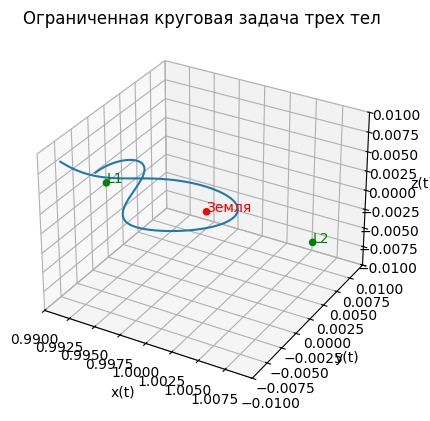

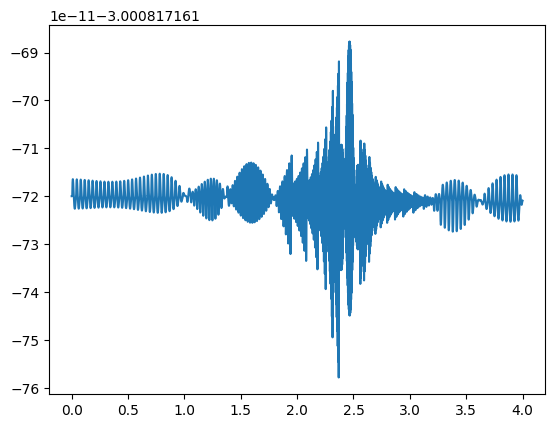

In [63]:
plotter = Plotter(system)
plotter.Plot(system)

С Дифф корректором

## Расчет и визуализация гало-орбиты с дифференциальной коррекцией

 Для уточнения этих начальных условий и достижения замкнутой орбиты, применяется метод дифференциальной коррекции. После корректировки мы решаем уравнения движения с новыми начальными условиями и визуализируем полученную траекторию, а также проверяем постоянство интеграла Якоби.

Step 1: Delta_xf = [-2.72550477e-03  7.13919506e-05]
Step 2: Delta_xf = [-1.63552989e-03  3.45996953e-05]
Step 3: Delta_xf = [-8.14320218e-04  1.72437494e-05]
Step 4: Delta_xf = [-3.68343021e-04  1.02610827e-05]
Step 5: Delta_xf = [-1.60284261e-04  7.42782580e-06]
Step 6: Delta_xf = [-7.01910794e-05  6.21626300e-06]
Step 7: Delta_xf = [-3.24425886e-05  5.65139846e-06]
Step 8: Delta_xf = [-1.67571628e-05  5.33088794e-06]
Step 9: Delta_xf = [-1.01605634e-05  5.10008520e-06]
Step 10: Delta_xf = [-7.32719270e-06  4.93474005e-06]


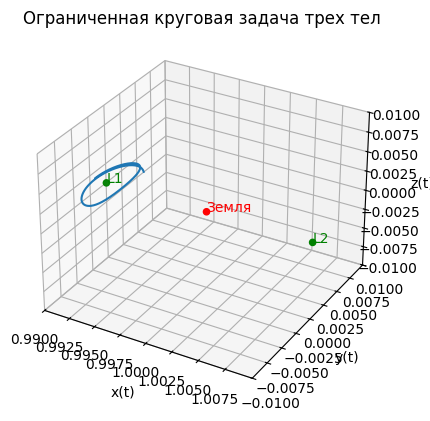

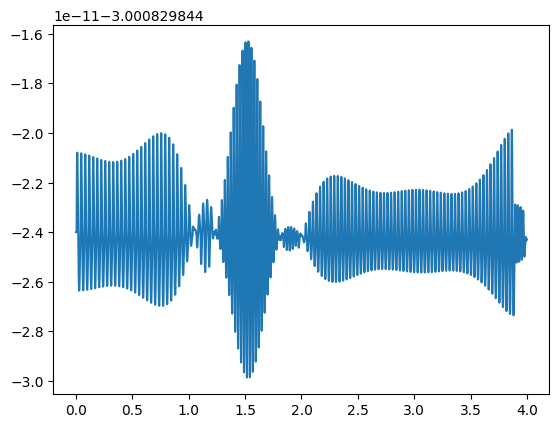

In [64]:
# Create an instance of the DifferentialCorrector
corrector = DifferentialCorrector(system)

# Perform differential correction
corrected_initial_state_vector = corrector.correct(initial_state_vector, Const.DEFAULT_TIME_LIMIT)

# Solve the final trajectory with the corrected initial conditions
system.SolveDI(corrected_initial_state_vector, Const.DEFAULT_TIME_LIMIT)
system.CaclulateJacobyIntegral()


plotter = Plotter(system)
plotter.Plot(system)